# Progetto 1 – Audit di fairness di un classificatore

**Come usare questo notebook**
- Esegui le celle **una alla volta, dall'alto verso il basso**: clicca sulla cella e premi `Shift + Invio`.
- Le celle grigie contengono codice: **non devi modificarlo**. Leggi i commenti (le righe che iniziano con `#`) per capire cosa fanno.
- Le celle di testo come questa ti spiegano cosa osservare. Dopo ogni risultato, annota le tue osservazioni nel tuo file di appunti.

**La domanda del progetto:** il modello prende decisioni ugualmente buone per uomini e donne, e per gruppi etnici diversi?

## Passo 0 – Preparazione
Installa la libreria per l'analisi di fairness. Ci vuole circa un minuto.

In [1]:
# Installa Fairlearn, la libreria che misura la fairness
!pip install -q fairlearn

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
from fairlearn.metrics import MetricFrame, selection_rate, count
from fairlearn.datasets import fetch_adult
print("Tutto pronto!")

Tutto pronto!


## Passo 1 – Caricare i dati
Usiamo il dataset **Adult Income**: circa 48.000 persone dal censimento USA del 1994. Per ognuna sappiamo età, istruzione, lavoro, ore lavorate, sesso, gruppo etnico… e se guadagna **più di 50.000 dollari l'anno** (sì/no).

Il modello dovrà prevedere proprio questo. Immagina che una banca lo usi per decidere a chi proporre un prestito: è un caso d'uso che l'AI Act considera **ad alto rischio** (valutazione del credito).

In [4]:
# Scarica il dataset (serve la connessione internet)
dati = fetch_adult(as_frame=True)
X = dati.data                                   # le caratteristiche delle persone
y = (dati.target == ">50K").astype(int)         # 1 = guadagna più di 50K, 0 = no

print("Numero di persone:", len(X))
print("Numero di caratteristiche:", X.shape[1])
X.head(10)

Numero di persone: 48842
Numero di caratteristiche: 14


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States
5,34,Private,198693,10th,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States
6,29,NaN,227026,HS-grad,9,Never-married,NaN,Unmarried,Black,Male,0,0,40,United-States
7,63,Self-emp-not-inc,104626,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,3103,0,32,United-States
8,24,Private,369667,Some-college,10,Never-married,Other-service,Unmarried,White,Female,0,0,40,United-States
9,55,Private,104996,7th-8th,4,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,10,United-States


## Passo 2 – Esplorare i dati: chi c'è dentro?
Prima di guardare il modello, guardiamo i dati. Ricorda dalla guida: **la qualità di un modello non può superare la qualità dei dati**.

**Cosa osservare:** i gruppi sono rappresentati in modo equilibrato? La quota di persone con reddito alto è simile tra i gruppi, o è già diversa nei dati?

In [3]:
# Quante persone per sesso, e che quota ha reddito alto
tabella_sesso = pd.DataFrame({
    "Persone": X["sex"].value_counts(),
    "Quota con reddito alto": y.groupby(X["sex"], observed=True).mean().round(3),
})
print("=== Per sesso ===")
print(tabella_sesso, "\n")

# Lo stesso per gruppo etnico
tabella_etnia = pd.DataFrame({
    "Persone": X["race"].value_counts(),
    "Quota con reddito alto": y.groupby(X["race"], observed=True).mean().round(3),
})
print("=== Per gruppo etnico ===")
print(tabella_etnia)

=== Per sesso ===
        Persone  Quota con reddito alto
sex                                    
Female    16192                   0.109
Male      32650                   0.304 

=== Per gruppo etnico ===
                    Persone  Quota con reddito alto
race                                               
Amer-Indian-Eskimo      470                   0.117
Asian-Pac-Islander     1519                   0.269
Black                  4685                   0.121
Other                   406                   0.123
White                 41762                   0.254


**Annota:** qual è il gruppo meno rappresentato? Che differenza vedi già nei dati tra uomini e donne? Questo è il *passato* che il modello imparerà.

## Passo 3 – Dividere i dati e addestrare il modello
Dividiamo i dati in **addestramento (70%)** e **test (30%)**, come nell'analogia dello studente.

**Una scelta importante:** togliamo dalle caratteristiche *sesso* ed *etnia*. Il modello quindi **non le vede**. Domanda da tenere a mente: basta questo a renderlo equo? (Ricorda la sezione "Indizi nascosti" della guida.)

In [5]:
# Teniamo da parte sesso ed etnia: servono a NOI per misurare, non al modello
gruppi = X[["sex", "race"]]
X_modello = X.drop(columns=["sex", "race"])

# Divisione 70% addestramento, 30% test (random_state fissa la divisione: risultati ripetibili)
X_train, X_test, y_train, y_test, gruppi_train, gruppi_test = train_test_split(
    X_modello, y, gruppi, test_size=0.3, random_state=42, stratify=y
)

# Un modello semplice: regressione logistica
modello = make_pipeline(
    make_column_transformer(
        (StandardScaler(), make_column_selector(dtype_include="number")),
        (OneHotEncoder(handle_unknown="ignore"), make_column_selector(dtype_exclude="number")),
    ),
    LogisticRegression(max_iter=1000),
)
modello.fit(X_train, y_train)

# Le previsioni sui dati di test, mai visti dal modello
previsioni = modello.predict(X_test)
print("Modello addestrato. Persone nel test:", len(X_test))

Modello addestrato. Persone nel test: 14653


## Passo 4 – Misurare il modello nel complesso
Ecco i numeri che conosci dalla guida. Qui il "caso positivo" è *reddito alto*: un **falso negativo** è una persona che guadagna bene ma il modello la scarta (e quindi non le verrebbe proposto il prestito).

In [6]:
print("Accuratezza:", round(accuracy_score(y_test, previsioni), 3))
print("Precision:  ", round(precision_score(y_test, previsioni), 3))
print("Recall:     ", round(recall_score(y_test, previsioni), 3))

tn, fp, fn, tp = confusion_matrix(y_test, previsioni).ravel()
print("\nMatrice di confusione")
print("Veri positivi:", tp, "| Falsi positivi:", fp)
print("Falsi negativi:", fn, "| Veri negativi:", tn)

Accuratezza: 0.855
Precision:   0.746
Recall:      0.598

Matrice di confusione
Veri positivi: 2098 | Falsi positivi: 715
Falsi negativi: 1408 | Veri negativi: 10432


**Annota:** l'accuratezza ti sembra buona? Ricorda la trappola: che quota di persone ha reddito alto in totale? Un modello "pigro" che dice sempre *no* che accuratezza avrebbe?

## Passo 5 – Il cuore dell'audit: misurare per gruppo (sesso)
Ora la domanda vera: **il modello funziona allo stesso modo per uomini e donne?**

- **Selection rate**: quota di persone a cui il modello dice *sì*.
- **Recall**: tra chi guadagna davvero bene, quanti il modello riconosce.
- **Precision**: quando dice *sì*, quanto ha ragione.

=== Risultati per sesso ===
        persone  accuratezza  precision  recall  selection rate
sex                                                            
Female   4857.0        0.929      0.769   0.542           0.080
Male     9796.0        0.818      0.742   0.609           0.247

=== Differenza massima tra i gruppi ===
accuratezza       0.111
precision         0.027
recall            0.066
selection rate    0.167
dtype: float64


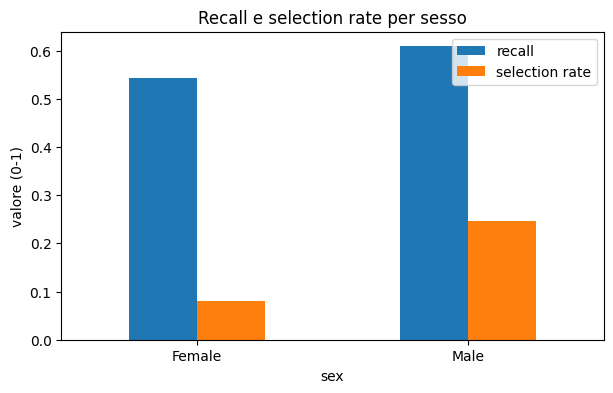

In [7]:
metriche = {
    "persone": count,
    "accuratezza": accuracy_score,
    "precision": precision_score,
    "recall": recall_score,
    "selection rate": selection_rate,
}

mf_sesso = MetricFrame(metrics=metriche, y_true=y_test, y_pred=previsioni,
                       sensitive_features=gruppi_test["sex"])
print("=== Risultati per sesso ===")
print(mf_sesso.by_group.round(3))
print("\n=== Differenza massima tra i gruppi ===")
print(mf_sesso.difference().drop("persone").round(3))

# Grafico per confrontare a colpo d'occhio
mf_sesso.by_group[["recall", "selection rate"]].plot(kind="bar", rot=0, figsize=(7, 4),
    title="Recall e selection rate per sesso")
plt.ylabel("valore (0-1)")
plt.show()

**Annota:** a quale gruppo il modello dice *sì* più spesso? Il recall è simile? Se è diverso, significa che tra le persone che guadagnano davvero bene, quelle di un gruppo vengono riconosciute meno spesso. Il modello non vedeva il sesso: come può essere?

## Passo 6 – Misurare per gruppo etnico
Ripetiamo l'analisi per gruppo etnico. **Attenzione al numero di persone per gruppo**: con pochi casi, le misure sono poco affidabili.

=== Risultati per gruppo etnico ===
                    persone  accuratezza  precision  recall  selection rate
race                                                                       
Amer-Indian-Eskimo    138.0        0.906      0.833   0.476           0.087
Asian-Pac-Islander    461.0        0.820      0.693   0.622           0.247
Black                1471.0        0.912      0.701   0.537           0.098
Other                 128.0        0.898      0.556   0.357           0.070
White               12455.0        0.849      0.751   0.603           0.203

=== Differenza massima tra i gruppi ===
accuratezza       0.092
precision         0.278
recall            0.265
selection rate    0.177
dtype: float64


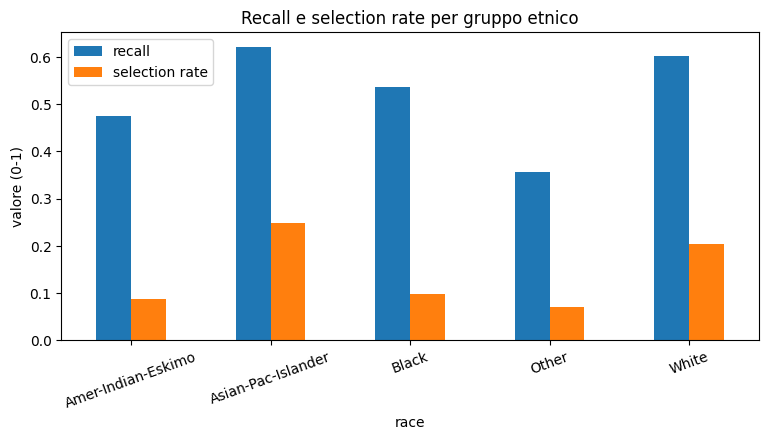

In [8]:
mf_etnia = MetricFrame(metrics=metriche, y_true=y_test, y_pred=previsioni,
                       sensitive_features=gruppi_test["race"])
print("=== Risultati per gruppo etnico ===")
print(mf_etnia.by_group.round(3))
print("\n=== Differenza massima tra i gruppi ===")
print(mf_etnia.difference().drop("persone").round(3))

mf_etnia.by_group[["recall", "selection rate"]].plot(kind="bar", rot=20, figsize=(9, 4),
    title="Recall e selection rate per gruppo etnico")
plt.ylabel("valore (0-1)")
plt.show()

**Annota:** quali gruppi hanno meno di qualche centinaio di persone nel test? Ti fideresti di quei numeri?

## Passo 7 – Le tue conclusioni
Il notebook ha finito il suo lavoro: ora tocca a te. Rispondi per iscritto, nel report:

1. Il modello nel complesso è buono? Con quali numeri lo dimostri?
2. Ci sono differenze importanti tra i gruppi? Quali, e quanto grandi?
3. Da dove pensi che nascano? (dati, rappresentatività, indizi nascosti…)
4. Togliere sesso ed etnia dalle caratteristiche è bastato?
5. Se fossi il QA responsabile, approveresti il rilascio? A quali condizioni?

Usa il modello di report nella guida al Progetto 1.